# UCS420: Cognitive Computing
## Assignment 10 - Diabetes Care Information Assistant

**Student Name:** Arnav Gupta  
**Roll Number:** 1024170057  
**Group:** 3Q25  
**Topic (odd roll number):** Diabetes Care Information Assistant

---

### Aim
To design and develop a Python-based **Healthcare Cognitive Assistant** that understands user queries about diabetes, identifies their intent, retrieves relevant information from a knowledge base and generates an appropriate response.

### Overall Architecture

```
User Query
    |
    v
[1] Safety Rules (emergency escalation)  --> emergency response
    |
    v
[2] NLP Preprocessing (lowercase, tokenize, stopwords, lemmatize)
    |
    v
[3] Unsupported-query check  --> polite refusal
    |
    v
[4] Intent Classification (TF-IDF + Logistic Regression)
    |
    v
[5] Low-confidence check  --> ask user to rephrase
    |
    v
[6] Knowledge Retrieval (TF-IDF similarity inside predicted intent)
    |
    v
[7] Reasoning (concept graph + glucose value interpretation)
    |
    v
Final Response (+ medical disclaimer)
```

> **Disclaimer:** This assistant is built only for educational purposes. It gives general information and is **not** a replacement for a doctor.

## 0. Importing Libraries
We use `NLTK` for the NLP steps, `scikit-learn` for TF-IDF and the classifier, `networkx` for the concept graph and `ipywidgets` for the chat interface in Colab.

In [29]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk

warnings.filterwarnings('ignore')

# NLTK resources (only downloaded once)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity

print("All libraries imported successfully")

All libraries imported successfully


## 1. Labelled Corpus (Requirement 1)

We created a corpus of **124 labelled queries** covering **6 intent categories** (about 20 queries per intent):

| Intent | Meaning |
|---|---|
| `symptoms_diagnosis` | Symptoms, types, risk factors and diagnosis of diabetes |
| `diet_nutrition` | Food choices, carbohydrates, meal planning |
| `medication_insulin` | Insulin, tablets, side effects, storage |
| `glucose_monitoring` | Blood sugar checking, target ranges, HbA1c, CGM |
| `complications_prevention` | Long-term complications and prevention |
| `lifestyle_exercise` | Exercise, weight, stress, sleep, habits |

In [30]:
corpus_data = [
    # ---------- symptoms_diagnosis ----------
    ("what are the early symptoms of diabetes", "symptoms_diagnosis"),
    ("why do i feel very thirsty and urinate frequently", "symptoms_diagnosis"),
    ("how is type 2 diabetes diagnosed", "symptoms_diagnosis"),
    ("what is the difference between type 1 and type 2 diabetes", "symptoms_diagnosis"),
    ("what are the warning signs of high blood sugar", "symptoms_diagnosis"),
    ("which tests are used to detect diabetes", "symptoms_diagnosis"),
    ("what is prediabetes and how do i know if i have it", "symptoms_diagnosis"),
    ("can blurred vision be a sign of diabetes", "symptoms_diagnosis"),
    ("what are the risk factors for developing diabetes", "symptoms_diagnosis"),
    ("do i have diabetes if i feel tired all the time", "symptoms_diagnosis"),
    ("what are the signs of diabetes in children", "symptoms_diagnosis"),
    ("what blood test confirms diabetes", "symptoms_diagnosis"),
    ("is frequent urination at night a symptom of diabetes", "symptoms_diagnosis"),
    ("what causes type 2 diabetes", "symptoms_diagnosis"),
    ("what are the common signs and symptoms of type 1 diabetes", "symptoms_diagnosis"),
    ("how do doctors diagnose diabetes", "symptoms_diagnosis"),
    ("what is the normal range to be called prediabetic", "symptoms_diagnosis"),
    ("who is at higher risk of getting diabetes", "symptoms_diagnosis"),
    ("is constant hunger and weight loss a symptom of diabetes", "symptoms_diagnosis"),
    ("what is gestational diabetes and how is it detected", "symptoms_diagnosis"),

    # ---------- diet_nutrition ----------
    ("what foods should a diabetic person eat", "diet_nutrition"),
    ("which fruits are safe for diabetes patients", "diet_nutrition"),
    ("how many carbohydrates can i eat per meal", "diet_nutrition"),
    ("can diabetics eat rice and chapati", "diet_nutrition"),
    ("what is the glycemic index of foods", "diet_nutrition"),
    ("suggest a healthy diet plan for diabetes", "diet_nutrition"),
    ("is sugar allowed in diabetes", "diet_nutrition"),
    ("what snacks are good for blood sugar control", "diet_nutrition"),
    ("should i avoid sweets completely if i have diabetes", "diet_nutrition"),
    ("what should i eat for breakfast if i am diabetic", "diet_nutrition"),
    ("are bananas and mangoes okay for diabetic patients", "diet_nutrition"),
    ("which vegetables are good for blood sugar", "diet_nutrition"),
    ("is brown rice better than white rice for diabetes", "diet_nutrition"),
    ("what is the best diet for type 2 diabetes", "diet_nutrition"),
    ("what can a diabetic eat for dinner", "diet_nutrition"),
    ("which foods should diabetic patients avoid", "diet_nutrition"),
    ("how much rice or roti can a diabetic person have", "diet_nutrition"),
    ("are sweets and chocolates harmful for diabetic patients", "diet_nutrition"),
    ("what are good low glycemic index foods", "diet_nutrition"),
    ("is fruit juice good for diabetic people", "diet_nutrition"),

    # ---------- medication_insulin ----------
    ("how does insulin work in the body", "medication_insulin"),
    ("what are the common side effects of metformin", "medication_insulin"),
    ("when do people with diabetes need to start insulin", "medication_insulin"),
    ("what are the different types of insulin", "medication_insulin"),
    ("how should i store insulin at home", "medication_insulin"),
    ("which tablets are used to treat type 2 diabetes", "medication_insulin"),
    ("what time should i take my diabetes medicine", "medication_insulin"),
    ("what happens if i miss a dose of insulin", "medication_insulin"),
    ("how do i inject insulin correctly", "medication_insulin"),
    ("how does metformin work to control sugar", "medication_insulin"),
    ("is metformin safe for long term use", "medication_insulin"),
    ("what are the side effects of insulin injections", "medication_insulin"),
    ("where on the body should insulin be injected", "medication_insulin"),
    ("should i take insulin before or after meals", "medication_insulin"),
    ("what is the first medicine given for type 2 diabetes", "medication_insulin"),
    ("how many types of insulin are there", "medication_insulin"),
    ("how do i store my insulin pen", "medication_insulin"),
    ("what are the side effects of diabetes tablets", "medication_insulin"),
    ("what should i do if i forget to take my medicine", "medication_insulin"),
    ("is insulin addictive or harmful", "medication_insulin"),
    ("what is metformin used for", "medication_insulin"),
    ("does metformin cause weight loss or stomach problems", "medication_insulin"),

    # ---------- glucose_monitoring ----------
    ("how often should i check my blood sugar", "glucose_monitoring"),
    ("what is a normal fasting blood glucose level", "glucose_monitoring"),
    ("what is hba1c and what is a good target", "glucose_monitoring"),
    ("how do i use a glucometer properly", "glucose_monitoring"),
    ("what is a continuous glucose monitor", "glucose_monitoring"),
    ("what should my blood sugar be after eating", "glucose_monitoring"),
    ("what blood sugar level is considered too low", "glucose_monitoring"),
    ("how to read my blood glucose test results", "glucose_monitoring"),
    ("when is the best time to test blood glucose", "glucose_monitoring"),
    ("my fasting sugar is 140 is that normal", "glucose_monitoring"),
    ("what is a normal blood sugar reading two hours after meals", "glucose_monitoring"),
    ("how do i read my hba1c report", "glucose_monitoring"),
    ("how many times a day should i test my glucose", "glucose_monitoring"),
    ("what is a good blood sugar range for diabetics", "glucose_monitoring"),
    ("what is the normal range of blood sugar", "glucose_monitoring"),
    ("how do i check my blood glucose at home", "glucose_monitoring"),
    ("what does a high hba1c value mean", "glucose_monitoring"),
    ("what is the target blood sugar before meals", "glucose_monitoring"),
    ("how does a cgm sensor measure glucose", "glucose_monitoring"),
    ("my sugar level is 160 after lunch is that high", "glucose_monitoring"),
    ("my sugar before breakfast was 120 is that okay", "glucose_monitoring"),
    ("is a reading of 110 after food normal", "glucose_monitoring"),

    # ---------- complications_prevention ----------
    ("what are the long term complications of diabetes", "complications_prevention"),
    ("how does diabetes damage the kidneys", "complications_prevention"),
    ("how can i prevent diabetic foot ulcers", "complications_prevention"),
    ("how does diabetes affect the eyes", "complications_prevention"),
    ("what is diabetic neuropathy", "complications_prevention"),
    ("how can i reduce my risk of heart disease with diabetes", "complications_prevention"),
    ("how often should i get my eyes checked", "complications_prevention"),
    ("how can i prevent type 2 diabetes", "complications_prevention"),
    ("how to take care of my feet if i have diabetes", "complications_prevention"),
    ("how does diabetes cause nerve damage", "complications_prevention"),
    ("why do diabetics get foot problems", "complications_prevention"),
    ("can diabetes lead to kidney failure", "complications_prevention"),
    ("how to avoid complications of diabetes", "complications_prevention"),
    ("how does diabetes affect the heart and blood pressure", "complications_prevention"),
    ("what happens to the eyes in a diabetic patient", "complications_prevention"),
    ("how can diabetes cause kidney damage", "complications_prevention"),
    ("why is foot care important in diabetes", "complications_prevention"),
    ("how can i protect my heart if i have diabetes", "complications_prevention"),
    ("what are the dangerous effects of uncontrolled diabetes", "complications_prevention"),
    ("how can i lower my chances of getting diabetes", "complications_prevention"),

    # ---------- lifestyle_exercise ----------
    ("how much exercise is good for diabetes", "lifestyle_exercise"),
    ("which exercises are best for people with diabetes", "lifestyle_exercise"),
    ("does walking after meals reduce blood sugar", "lifestyle_exercise"),
    ("how does stress affect blood sugar", "lifestyle_exercise"),
    ("can losing weight reverse type 2 diabetes", "lifestyle_exercise"),
    ("how does lack of sleep affect diabetes", "lifestyle_exercise"),
    ("is yoga helpful for diabetes control", "lifestyle_exercise"),
    ("is it safe to exercise when blood sugar is high", "lifestyle_exercise"),
    ("does smoking or alcohol affect diabetes", "lifestyle_exercise"),
    ("how many minutes should i walk every day with diabetes", "lifestyle_exercise"),
    ("can meditation or yoga help lower my sugar", "lifestyle_exercise"),
    ("does being overweight increase blood sugar", "lifestyle_exercise"),
    ("is it okay to drink alcohol if i have diabetes", "lifestyle_exercise"),
    ("how can i manage stress and sleep better with diabetes", "lifestyle_exercise"),
    ("what type of exercise is best for blood sugar control", "lifestyle_exercise"),
    ("is walking good for diabetic patients", "lifestyle_exercise"),
    ("can yoga and meditation reduce stress and sugar", "lifestyle_exercise"),
    ("how does weight loss help in diabetes", "lifestyle_exercise"),
    ("how many hours of sleep do i need with diabetes", "lifestyle_exercise"),
    ("should diabetics stop smoking and drinking", "lifestyle_exercise"),
]

df = pd.DataFrame(corpus_data, columns=["query", "intent"])
print("Total queries :", len(df))
print("Total intents :", df['intent'].nunique())
print()
print(df['intent'].value_counts())
df.sample(8, random_state=1)

Total queries : 124
Total intents : 6

intent
glucose_monitoring          22
medication_insulin          22
diet_nutrition              20
symptoms_diagnosis          20
complications_prevention    20
lifestyle_exercise          20
Name: count, dtype: int64


,query,intent
48,how do i inject insulin correctly,medication_insulin
114,can meditation or yoga help lower my sugar,lifestyle_exercise
73,how do i read my hba1c report,glucose_monitoring
106,does walking after meals reduce blood sugar,lifestyle_exercise
45,which tablets are used to treat type 2 diabetes,medication_insulin
31,which vegetables are good for blood sugar,diet_nutrition
67,what should my blood sugar be after eating,glucose_monitoring
46,what time should i take my diabetes medicine,medication_insulin


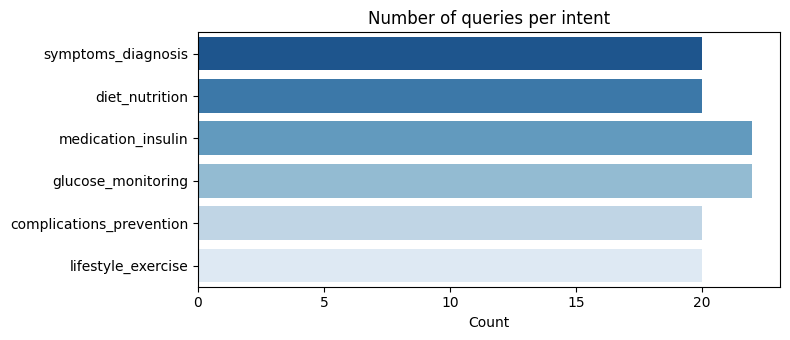

In [31]:
# distribution of the corpus
plt.figure(figsize=(8, 3.5))
sns.countplot(y='intent', data=df, palette='Blues_r')
plt.title("Number of queries per intent")
plt.xlabel("Count")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 2. Hierarchical Taxonomy (Requirement 2)

The taxonomy has **6 major categories**, and each has **3 subcategories** (the requirement was at least 4 and 2). Every intent in our corpus is mapped to one of the taxonomy nodes.

In [32]:
taxonomy = {
    "Understanding Diabetes": [
        "Types of Diabetes (Type 1, Type 2, Gestational)",
        "Symptoms and Diagnosis",
        "Risk Factors and Prediabetes",
    ],
    "Nutrition and Diet": [
        "Carbohydrate Management",
        "Food Choices and Glycemic Index",
        "Meal Planning and Snacks",
    ],
    "Treatment and Medication": [
        "Insulin Therapy",
        "Oral Medications (Metformin etc.)",
        "Medication Safety and Storage",
    ],
    "Monitoring and Self-Management": [
        "Blood Glucose Testing (Glucometer, CGM)",
        "HbA1c and Lab Tests",
        "Target Ranges and Hypoglycemia",
    ],
    "Complications and Prevention": [
        "Eye, Kidney and Nerve Complications",
        "Heart Health and Foot Care",
        "Preventing Type 2 Diabetes",
    ],
    "Lifestyle and Wellness": [
        "Physical Activity",
        "Weight, Sleep and Stress",
        "Smoking and Alcohol",
    ],
}

# mapping each intent to its taxonomy category
intent_to_category = {
    "symptoms_diagnosis":       "Understanding Diabetes",
    "diet_nutrition":           "Nutrition and Diet",
    "medication_insulin":       "Treatment and Medication",
    "glucose_monitoring":       "Monitoring and Self-Management",
    "complications_prevention": "Complications and Prevention",
    "lifestyle_exercise":       "Lifestyle and Wellness",
}

# print the tree
print("DIABETES CARE TAXONOMY")
print("=" * 50)
for i, (cat, subs) in enumerate(taxonomy.items(), 1):
    print(f"{i}. {cat}")
    for j, s in enumerate(subs):
        branch = "`--" if j == len(subs) - 1 else "|--"
        print(f"   {branch} {s}")
print("=" * 50)
print("Major categories :", len(taxonomy))
print("Sub-categories   :", sum(len(v) for v in taxonomy.values()))
assert len(taxonomy) >= 4 and all(len(v) >= 2 for v in taxonomy.values())

DIABETES CARE TAXONOMY
1. Understanding Diabetes
   |-- Types of Diabetes (Type 1, Type 2, Gestational)
   |-- Symptoms and Diagnosis
   `-- Risk Factors and Prediabetes
2. Nutrition and Diet
   |-- Carbohydrate Management
   |-- Food Choices and Glycemic Index
   `-- Meal Planning and Snacks
3. Treatment and Medication
   |-- Insulin Therapy
   |-- Oral Medications (Metformin etc.)
   `-- Medication Safety and Storage
4. Monitoring and Self-Management
   |-- Blood Glucose Testing (Glucometer, CGM)
   |-- HbA1c and Lab Tests
   `-- Target Ranges and Hypoglycemia
5. Complications and Prevention
   |-- Eye, Kidney and Nerve Complications
   |-- Heart Health and Foot Care
   `-- Preventing Type 2 Diabetes
6. Lifestyle and Wellness
   |-- Physical Activity
   |-- Weight, Sleep and Stress
   `-- Smoking and Alcohol
Major categories : 6
Sub-categories   : 18


## 3. Domain Concepts and Relationships (Requirement 3)

We identified **17 domain concepts** and defined **18 relationships** between them. These are stored as a small knowledge graph (`networkx`). Later, the reasoning module of the assistant walks through this graph to add related facts to an answer.

In [33]:
# concept -> list of words/aliases that can appear in a query
concepts = {
    "Diabetes Mellitus":  ["diabetes", "diabetic", "sugar patient"],
    "Insulin":            ["insulin"],
    "Pancreas":           ["pancreas"],
    "Blood Glucose":      ["blood sugar", "glucose", "sugar level", "blood glucose"],
    "HbA1c":              ["hba1c", "a1c"],
    "Insulin Resistance": ["insulin resistance", "resistance"],
    "Hypoglycemia":       ["hypoglycemia", "low sugar", "low blood sugar", "hypo"],
    "Hyperglycemia":      ["hyperglycemia", "high sugar", "high blood sugar"],
    "Obesity":            ["obesity", "overweight", "weight"],
    "Carbohydrates":      ["carbohydrate", "carb", "rice", "chapati", "roti", "bread"],
    "Exercise":           ["exercise", "walking", "yoga", "workout", "physical activity"],
    "Metformin":          ["metformin"],
    "Neuropathy":         ["neuropathy", "nerve", "numbness", "tingling"],
    "Retinopathy":        ["retinopathy", "eye", "vision"],
    "Nephropathy":        ["nephropathy", "kidney"],
    "Glycemic Index":     ["glycemic index", "gi"],
    "Glucometer":         ["glucometer", "cgm", "glucose monitor"],
}

# (subject, relation, object)
relationships = [
    ("Pancreas",           "produces",            "Insulin"),
    ("Insulin",            "lowers",              "Blood Glucose"),
    ("Insulin",            "can cause",           "Hypoglycemia"),
    ("Carbohydrates",      "raise",               "Blood Glucose"),
    ("Glycemic Index",     "ranks",               "Carbohydrates"),
    ("Exercise",           "lowers",              "Blood Glucose"),
    ("Exercise",           "reduces",             "Insulin Resistance"),
    ("Obesity",            "increases",           "Insulin Resistance"),
    ("Insulin Resistance", "leads to",            "Diabetes Mellitus"),
    ("Diabetes Mellitus",  "causes",              "Hyperglycemia"),
    ("Hyperglycemia",      "causes",              "Neuropathy"),
    ("Hyperglycemia",      "causes",              "Retinopathy"),
    ("Hyperglycemia",      "causes",              "Nephropathy"),
    ("Metformin",          "treats",              "Diabetes Mellitus"),
    ("Metformin",          "reduces",             "Insulin Resistance"),
    ("HbA1c",              "shows average of",    "Blood Glucose"),
    ("Glucometer",         "measures",            "Blood Glucose"),
    ("Diabetes Mellitus",  "is monitored using",  "HbA1c"),
]

print("Number of concepts      :", len(concepts))
print("Number of relationships :", len(relationships))
assert len(concepts) >= 8 and len(relationships) >= 10

pd.DataFrame(relationships, columns=["Subject", "Relation", "Object"])

Number of concepts      : 17
Number of relationships : 18


,Subject,Relation,Object
0,Pancreas,produces,Insulin
1,Insulin,lowers,Blood Glucose
2,Insulin,can cause,Hypoglycemia
3,Carbohydrates,raise,Blood Glucose
4,Glycemic Index,ranks,Carbohydrates
5,Exercise,lowers,Blood Glucose
6,Exercise,reduces,Insulin Resistance
7,Obesity,increases,Insulin Resistance
8,Insulin Resistance,leads to,Diabetes Mellitus
9,Diabetes Mellitus,causes,Hyperglycemia


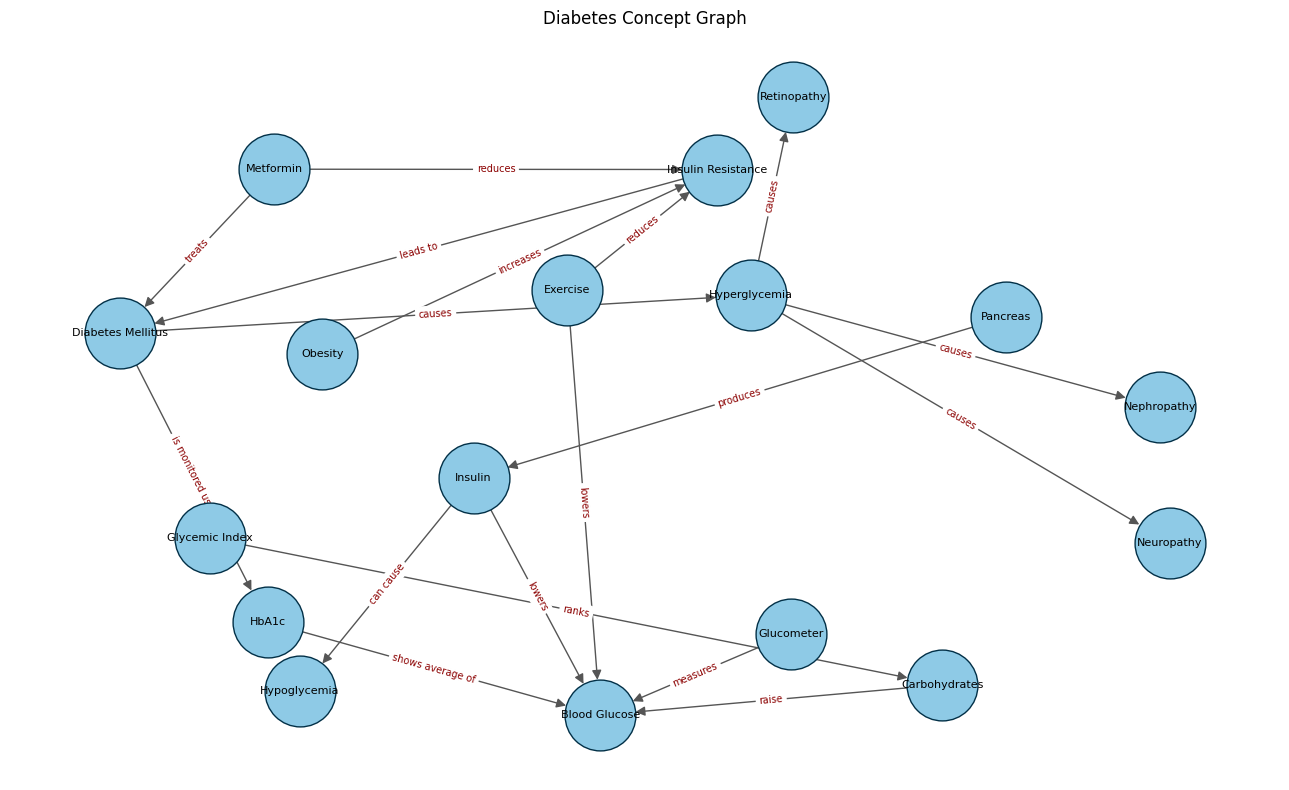

In [34]:
# build the knowledge graph
G = nx.DiGraph()
for c in concepts:
    G.add_node(c)
for s, r, o in relationships:
    G.add_edge(s, o, relation=r)

plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=7, k=1.2)
nx.draw_networkx_nodes(G, pos, node_color="#8ecae6", node_size=2600, edgecolors="#023047")
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrowstyle="-|>", arrowsize=14, edge_color="#555", node_size=2600)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "relation"),
                             font_size=7, font_color="darkred")
plt.title("Diabetes Concept Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Text Preprocessing (Requirement 4)

The pipeline has four steps:
1. **Lowercase conversion**
2. **Tokenization** (NLTK `word_tokenize`, after removing punctuation)
3. **Stopword removal** (NLTK English stopwords; we *keep* words like `no`, `not`, `before`, `after`, `low`, `high` since they change the meaning of health queries)
4. **Lemmatization** (WordNet lemmatizer, e.g. `tablets -> tablet`, `feet -> foot`, `eating -> eat`)

In [35]:
# keep some words that carry meaning in health queries
KEEP_WORDS = {"no", "not", "nor", "before", "after", "low", "high"}
STOP_WORDS = set(stopwords.words("english")) - KEEP_WORDS
lemmatizer = WordNetLemmatizer()

def preprocess(text, show_steps=False):
    # step 1: lowercase
    lowered = text.lower()

    # remove punctuation / special characters
    no_punct = re.sub(r"[^a-z0-9\s]", " ", lowered)

    # step 2: tokenization
    tokens = word_tokenize(no_punct)

    # step 3: stopword removal
    no_stop = [t for t in tokens if t not in STOP_WORDS]

    # step 4: lemmatization (verb first, then noun)
    lemmas = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in no_stop]

    if show_steps:
        print("Original   :", text)
        print("Lowercase  :", lowered)
        print("Tokens     :", tokens)
        print("No stopword:", no_stop)
        print("Lemmatized :", lemmas)
    return " ".join(lemmas)

# quick demo of every step
_ = preprocess("How Often Should I Check My Blood Sugar After Eating Sweets?", show_steps=True)
print()
_ = preprocess("What are the common side effects of the tablets for my feet?", show_steps=True)

Original   : How Often Should I Check My Blood Sugar After Eating Sweets?
Lowercase  : how often should i check my blood sugar after eating sweets?
Tokens     : ['how', 'often', 'should', 'i', 'check', 'my', 'blood', 'sugar', 'after', 'eating', 'sweets']
No stopword: ['often', 'check', 'blood', 'sugar', 'after', 'eating', 'sweets']
Lemmatized : ['often', 'check', 'blood', 'sugar', 'after', 'eat', 'sweet']

Original   : What are the common side effects of the tablets for my feet?
Lowercase  : what are the common side effects of the tablets for my feet?
Tokens     : ['what', 'are', 'the', 'common', 'side', 'effects', 'of', 'the', 'tablets', 'for', 'my', 'feet']
No stopword: ['common', 'side', 'effects', 'tablets', 'feet']
Lemmatized : ['common', 'side', 'effect', 'tablet', 'foot']


In [36]:
# apply to the whole corpus
df["clean"] = df["query"].apply(preprocess)
df[["query", "clean", "intent"]].head(10)

,query,clean,intent
0,what are the early symptoms of diabetes,early symptom diabetes,symptoms_diagnosis
1,why do i feel very thirsty and urinate frequently,feel thirsty urinate frequently,symptoms_diagnosis
2,how is type 2 diabetes diagnosed,type 2 diabetes diagnose,symptoms_diagnosis
3,what is the difference between type 1 and type...,difference type 1 type 2 diabetes,symptoms_diagnosis
4,what are the warning signs of high blood sugar,warn sign high blood sugar,symptoms_diagnosis
5,which tests are used to detect diabetes,test use detect diabetes,symptoms_diagnosis
6,what is prediabetes and how do i know if i hav...,prediabetes know,symptoms_diagnosis
7,can blurred vision be a sign of diabetes,blur vision sign diabetes,symptoms_diagnosis
8,what are the risk factors for developing diabetes,risk factor develop diabetes,symptoms_diagnosis
9,do i have diabetes if i feel tired all the time,diabetes feel tire time,symptoms_diagnosis


## 5. TF-IDF Feature Extraction and Model Training (Requirement 5)

- **Feature extraction:** TF-IDF (unigrams, sublinear tf scaling). We tried bigrams too, but with such a small corpus they did not improve the cross-validation score
- **Classifiers compared:** Multinomial Naive Bayes, Logistic Regression, Linear SVM
- The data is split 80% train / 20% test (stratified so that every intent appears in both sets).
- We also run 5-fold cross validation on the full corpus because the dataset is small.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.2, random_state=42, stratify=df["intent"])

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

tfidf = TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("TF-IDF matrix shape (train):", X_train_tfidf.shape)

# top weighted terms for a sample query
sample = tfidf.transform([preprocess("how often should i check my blood sugar")])
terms = np.array(tfidf.get_feature_names_out())
nz = sample.nonzero()[1]
print("\nTF-IDF weights for 'how often should i check my blood sugar':")
for i in sorted(nz, key=lambda k: -sample[0, k])[:6]:
    print(f"   {terms[i]:<22} {sample[0, i]:.3f}")

Training samples: 99
Testing samples : 25
TF-IDF matrix shape (train): (99, 168)

TF-IDF weights for 'how often should i check my blood sugar':
   often                  0.637
   check                  0.584
   blood                  0.367
   sugar                  0.345


In [38]:
# compare the three classifiers
models = {
    "Naive Bayes":         MultinomialNB(alpha=1.0),
    "Logistic Regression": LogisticRegression(C=30, max_iter=1000),
    "Linear SVM":          LinearSVC(C=3.0),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, mdl in models.items():
    mdl.fit(X_train_tfidf, y_train)
    test_acc = accuracy_score(y_test, mdl.predict(X_test_tfidf))
    # cross validation using the full corpus (vectorizer is fit inside each fold)
    from sklearn.pipeline import make_pipeline
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True), mdl)
    cv = cross_val_score(pipe, df["clean"], df["intent"], cv=skf, scoring="accuracy")
    rows.append([name, round(test_acc, 3), round(cv.mean(), 3), round(cv.std(), 3)])

comparison = pd.DataFrame(rows, columns=["Model", "Test Accuracy", "CV Mean Accuracy", "CV Std"])
comparison

,Model,Test Accuracy,CV Mean Accuracy,CV Std
0,Naive Bayes,0.76,0.718,0.104
1,Logistic Regression,0.80,0.758,0.099
2,Linear SVM,0.80,0.733,0.067


We selected **Logistic Regression** as the final model. Along with good accuracy it gives class **probabilities**, which are needed for the low-confidence rule in the assistant.

In [39]:
clf = LogisticRegression(C=30, max_iter=1000)
clf.fit(X_train_tfidf, y_train)
y_pred = clf.predict(X_test_tfidf)
print("Final model trained:", clf)

Final model trained: LogisticRegression(C=30, max_iter=1000)


## 6. Model Evaluation (Requirement 6)

Metrics used: **accuracy, precision, recall, F1-score** (macro averaged) and a **confusion matrix**.

In [40]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec  = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1   = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Accuracy  : {acc:.3f}")
print(f"Precision : {prec:.3f}   (macro)")
print(f"Recall    : {rec:.3f}   (macro)")
print(f"F1-score  : {f1:.3f}   (macro)")
print()
print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy  : 0.800
Precision : 0.854   (macro)
Recall    : 0.800   (macro)
F1-score  : 0.813   (macro)

Classification report:
                          precision    recall  f1-score   support

complications_prevention       1.00      0.75      0.86         4
          diet_nutrition       1.00      0.75      0.86         4
      glucose_monitoring       0.57      0.80      0.67         5
      lifestyle_exercise       1.00      0.75      0.86         4
      medication_insulin       0.80      1.00      0.89         4
      symptoms_diagnosis       0.75      0.75      0.75         4

                accuracy                           0.80        25
               macro avg       0.85      0.80      0.81        25
            weighted avg       0.84      0.80      0.81        25



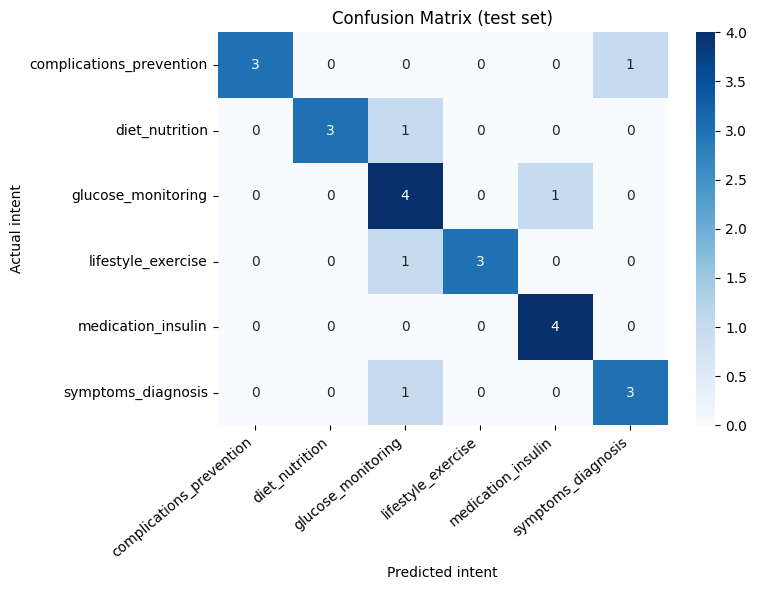

In [41]:
labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Confusion Matrix (test set)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The classifier separates the six intents well because each intent uses fairly distinct vocabulary (for example *insulin, metformin* for medication, *exercise, walking* for lifestyle). Any mistakes are normally between related intents such as `glucose_monitoring` and `symptoms_diagnosis`, which both talk about blood sugar levels. Since the corpus is small (124 queries), the test set is only 25 samples, so the scores can change a bit with a different random split. That is why we also report cross-validation above.

For the final assistant we re-train the model on the **complete corpus** so it can learn from every example.

In [42]:
# final model on the whole corpus (used by the assistant)
final_tfidf = TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True)
X_all = final_tfidf.fit_transform(df["clean"])
final_clf = LogisticRegression(C=30, max_iter=1000)
final_clf.fit(X_all, df["intent"])
print("Final classifier trained on", X_all.shape[0], "queries,", X_all.shape[1], "features")

Final classifier trained on 124 queries, 192 features


## 7. Domain Knowledge Base (Requirement 7)

For every intent we wrote several knowledge entries (38 entries in total). Each entry has a **topic**, some **keywords** and the **information text**. The facts are general guidelines (mostly based on commonly published diabetes guidance such as ADA / WHO). Retrieval is done later using TF-IDF cosine similarity.

In [43]:
knowledge_base = [
  # ======================= symptoms_diagnosis =======================
  {"intent": "symptoms_diagnosis", "topic": "Common symptoms of diabetes",
   "keywords": "symptom sign early thirsty thirst urinate urination hungry hunger tired fatigue blurred vision weight loss tingling slow healing infection",
   "text": "Common symptoms are increased thirst, frequent urination, extreme hunger, unexplained weight loss, tiredness, blurred vision, slow-healing cuts, frequent infections and tingling in hands or feet. In type 1 diabetes symptoms appear quickly, while in type 2 they can develop slowly and may go unnoticed for years."},
  {"intent": "symptoms_diagnosis", "topic": "Types of diabetes",
   "keywords": "type 1 type 2 gestational difference types autoimmune pancreas",
   "text": "Type 1: an autoimmune condition where the pancreas makes little or no insulin; it usually starts in childhood or young adulthood and needs insulin. Type 2: the body becomes resistant to insulin or does not make enough; it is the most common type and is linked to excess weight, inactivity and family history. Gestational diabetes appears during pregnancy and usually goes away after delivery, but raises the later risk of type 2."},
  {"intent": "symptoms_diagnosis", "topic": "How diabetes is diagnosed",
   "keywords": "diagnose diagnosis diagnosed test detect confirm confirmed doctor fasting plasma glucose hba1c ogtt glucose tolerance do i have diabetes",
   "text": "Diabetes is diagnosed with blood tests: fasting plasma glucose of 126 mg/dL or more, HbA1c of 6.5% or more, a 2-hour glucose of 200 mg/dL or more in an oral glucose tolerance test, or a random glucose of 200 mg/dL or more with classic symptoms. In the absence of clear symptoms the test is normally repeated to confirm."},
  {"intent": "symptoms_diagnosis", "topic": "Prediabetes",
   "keywords": "prediabetes borderline pre diabetes risk reversible",
   "text": "Prediabetes means blood sugar is higher than normal but not yet in the diabetes range: fasting glucose 100-125 mg/dL or HbA1c 5.7-6.4%. It usually has no symptoms. Weight loss, healthy eating and regular activity can prevent or delay progression to type 2 diabetes."},
  {"intent": "symptoms_diagnosis", "topic": "Risk factors",
   "keywords": "risk factor cause develop family history overweight age pcos pressure",
   "text": "Major risk factors are overweight or obesity (especially belly fat), family history of diabetes, age above 45, physical inactivity, high blood pressure, PCOS, diabetes during a previous pregnancy and South Asian ethnicity. Having risk factors does not mean you will definitely get diabetes, but screening is advised."},

  # ======================= diet_nutrition =======================
  {"intent": "diet_nutrition", "topic": "Healthy food choices",
   "keywords": "food eat diet plan healthy vegetable whole grain protein nuts plate",
   "text": "A diabetes-friendly plate has half non-starchy vegetables, one quarter lean protein (dal, eggs, fish, paneer, chicken) and one quarter whole grains. Good choices are leafy vegetables, legumes, oats, nuts and seeds. Limit refined flour, sugary drinks, fried and processed foods."},
  {"intent": "diet_nutrition", "topic": "Carbohydrate counting and portions",
   "keywords": "carbohydrate carb count meal portion gram per meal",
   "text": "Carbohydrates raise blood sugar the most, so the amount and timing matter. Many adults are advised about 45-60 g of carbohydrate per meal as a general starting range, but your own target depends on your medicines, weight and activity, so a dietitian should set it. Eating carbs at regular times helps keep sugar steady."},
  {"intent": "diet_nutrition", "topic": "Glycemic index",
   "keywords": "glycemic index gi low high food rank",
   "text": "The glycemic index (GI) ranks foods by how quickly they raise blood sugar. Low GI (55 or less): oats, lentils, most vegetables, apples. High GI (70 or more): white bread, white rice, sugary drinks. Pairing carbs with fibre and protein slows the rise in sugar."},
  {"intent": "diet_nutrition", "topic": "Fruits for diabetes",
   "keywords": "fruit apple guava berries mango banana grapes juice safe",
   "text": "Whole fruits can be eaten in controlled portions. Better choices are apples, guava, pears, berries, oranges and papaya. Be careful with portion size of mango, banana, grapes and chikoo, and avoid fruit juices because they raise sugar quickly and have no fibre."},
  {"intent": "diet_nutrition", "topic": "Rice, chapati and Indian staples",
   "keywords": "rice chapati roti bread paratha millet brown indian staple dal",
   "text": "Rice and chapati are not banned, but portion and type matter. Prefer whole-wheat or multigrain chapati, brown rice or millets (ragi, jowar, bajra) in a small portion, and always combine them with dal and vegetables. Avoid large servings of white rice, naan and maida-based items."},
  {"intent": "diet_nutrition", "topic": "Sugar, sweets and snacks",
   "keywords": "sugar sweet dessert snack allowed avoid mithai chocolate skip meal",
   "text": "Sweets do not have to be avoided completely; a small portion occasionally, as part of a planned meal, is usually fine. Sugary drinks should be avoided. Healthy snacks are roasted chana, nuts, sprouts, curd, cucumber or vegetable sticks. Do not skip meals, especially if you take insulin or sugar-lowering tablets."},

  # ======================= medication_insulin =======================
  {"intent": "medication_insulin", "topic": "How insulin works",
   "keywords": "insulin work body hormone cell pancreas function",
   "text": "Insulin is a hormone made by the pancreas. It helps the body's cells take up glucose from the blood to use as energy, so blood sugar falls. In diabetes the body makes too little insulin or cannot use it properly, so insulin injections (or other medicines) are used to control sugar."},
  {"intent": "medication_insulin", "topic": "Types of insulin",
   "keywords": "type insulin rapid short long intermediate premixed glargine nph different",
   "text": "Insulins differ by how fast they start and how long they last: rapid-acting (meal-time), short-acting (regular), intermediate-acting (NPH), long-acting (glargine, detemir, degludec) and premixed insulins. Your doctor chooses the type and schedule based on your needs."},
  {"intent": "medication_insulin", "topic": "When insulin is needed",
   "keywords": "start insulin need when begin type 2 tablets fail hba1c",
   "text": "People with type 1 diabetes need insulin from the start. People with type 2 diabetes may need insulin when tablets are no longer enough, when HbA1c stays high, during pregnancy, serious illness or surgery. The decision is always taken by the doctor."},
  {"intent": "medication_insulin", "topic": "Metformin and its side effects",
   "keywords": "metformin side effect nausea diarrhea stomach upset tablet first line",
   "text": "Metformin is usually the first medicine for type 2 diabetes. It reduces sugar made by the liver and improves insulin sensitivity. Common side effects are nausea, loose stools, stomach upset and a metallic taste, which often improve if it is taken with food. Long-term use can lower vitamin B12, and it should be used carefully in kidney problems."},
  {"intent": "medication_insulin", "topic": "Other diabetes tablets",
   "keywords": "tablet oral medicine drug sulfonylurea sglt2 dpp4 glp1 treat type 2",
   "text": "Besides metformin, other drug groups include sulfonylureas (can cause low sugar), DPP-4 inhibitors, SGLT2 inhibitors (can cause genital infections and dehydration) and GLP-1 medicines. Which one is suitable depends on your sugar levels, heart and kidney health, so only a doctor should select it."},
  {"intent": "medication_insulin", "topic": "Insulin storage and injection technique",
   "keywords": "store storage fridge inject injection pen needle site rotate how",
   "text": "Keep unopened insulin in the refrigerator (2-8 C) and never freeze it. The pen or vial currently in use can be kept at room temperature for the period given on the label (about 28 days for most). Inject into the abdomen, thigh or upper arm, rotate the injection site each time and use a fresh needle for every injection."},
  {"intent": "medication_insulin", "topic": "Missed dose, timing and dose changes",
   "keywords": "miss missed dose forget forgot forgotten skip late time when take schedule double increase decrease change adjust insulin injection medicine",
   "text": "Take medicines at the time prescribed by your doctor, usually at the same time every day. If you miss a dose, the correct action depends on the medicine (for example, rapid-acting insulin is different from long-acting insulin). Do not take a double dose to make up for it. Any increase or decrease in dose must be decided by your doctor based on your sugar readings. Call your doctor or pharmacist for advice."},

  # ======================= glucose_monitoring =======================
  {"intent": "glucose_monitoring", "topic": "How often to check blood sugar",
   "keywords": "often frequency check test monitor how many times daily insulin",
   "text": "How often you test depends on the type of diabetes and treatment. People on insulin may test several times a day (before meals and at bedtime), while people with type 2 diabetes on tablets may test less often. Your doctor will give you a personal schedule."},
  {"intent": "glucose_monitoring", "topic": "Normal and target blood sugar levels",
   "keywords": "normal fasting target range level after eating postprandial before meal good reading result okay value mg dl high breakfast",
   "text": "For people without diabetes, fasting sugar is below 100 mg/dL and 2 hours after meals it is below 140 mg/dL. A common target for adults with diabetes is 80-130 mg/dL before meals and below 180 mg/dL two hours after a meal, but targets are individualised by the doctor."},
  {"intent": "glucose_monitoring", "topic": "HbA1c test",
   "keywords": "hba1c a1c average three months target glycated haemoglobin lab",
   "text": "HbA1c shows the average blood sugar over the last 2-3 months. Below 5.7% is normal, 5.7-6.4% is prediabetes and 6.5% or more is in the diabetes range. For many adults with diabetes a target below 7% is advised. It is usually checked every 3-6 months."},
  {"intent": "glucose_monitoring", "topic": "Using a glucometer",
   "keywords": "glucometer use strip finger prick lancet meter properly test how",
   "text": "Wash and dry your hands, insert a test strip, prick the side of your fingertip with a lancet, touch the drop of blood to the strip and read the result. Check the strip expiry date, do not reuse lancets and write the readings in a log to show your doctor."},
  {"intent": "glucose_monitoring", "topic": "Continuous glucose monitor (CGM)",
   "keywords": "continuous glucose monitor cgm sensor libre dexcom trend alarm",
   "text": "A CGM uses a small sensor under the skin that measures sugar every few minutes and shows trends and alarms for highs and lows on a reader or phone. It reduces the number of finger pricks, although a finger-prick test may still be needed to confirm readings in some situations."},
  {"intent": "glucose_monitoring", "topic": "Low blood sugar (hypoglycemia)",
   "keywords": "low blood sugar hypoglycemia hypo too low level 70 54 shaky sweating treat",
   "text": "A blood sugar below 70 mg/dL is considered low (hypoglycemia) and below 54 mg/dL is serious. Symptoms are shakiness, sweating, hunger, dizziness and confusion. Follow the rule of 15: take 15 g of fast sugar (3-4 glucose tablets or half a cup of juice), re-check after 15 minutes and repeat if still low."},
  {"intent": "glucose_monitoring", "topic": "Best time to test",
   "keywords": "best time when test timing morning bedtime before after meal exercise sick",
   "text": "Useful times are fasting (first thing in the morning), before meals, 2 hours after meals, at bedtime, before and after exercise and whenever you feel unwell or have symptoms of low or high sugar."},

  # ======================= complications_prevention =======================
  {"intent": "complications_prevention", "topic": "Long-term complications overview",
   "keywords": "long term complication problem damage risk overview",
   "text": "When blood sugar stays high for years it can damage blood vessels and nerves. Main complications are heart disease and stroke, kidney disease (nephropathy), eye disease (retinopathy), nerve damage (neuropathy), foot problems and gum disease. Good control of sugar, blood pressure and cholesterol greatly lowers these risks."},
  {"intent": "complications_prevention", "topic": "Kidney damage (nephropathy)",
   "keywords": "kidney nephropathy renal urine albumin egfr damage",
   "text": "High sugar and high blood pressure damage the tiny filters of the kidneys. Early kidney disease has no symptoms, so a urine albumin test and an eGFR blood test should be done at least once a year. Controlling blood pressure and sugar slows the damage."},
  {"intent": "complications_prevention", "topic": "Eye problems (retinopathy)",
   "keywords": "eye retinopathy vision blind cataract glaucoma check retina exam",
   "text": "Diabetes can damage the retina (diabetic retinopathy) and also increases the risk of cataract and glaucoma. A dilated eye examination should be done at diagnosis and then at least once a year, or as advised by the eye doctor, because early damage can be treated."},
  {"intent": "complications_prevention", "topic": "Diabetic neuropathy",
   "keywords": "neuropathy nerve numbness tingling burning pain feet damage",
   "text": "Diabetic neuropathy is nerve damage caused by long-standing high sugar. It most often causes numbness, tingling or burning pain in the feet and hands. Keeping sugar in range slows it down, and any new numbness or pain should be reported to the doctor."},
  {"intent": "complications_prevention", "topic": "Foot care",
   "keywords": "foot feet ulcer wound care shoes toe nail barefoot prevent",
   "text": "Check your feet every day for cuts, blisters, redness or swelling. Wash and dry them well (including between the toes), moisturise the skin but not between the toes, wear well-fitting shoes and socks, never walk barefoot and cut nails straight across. See a doctor quickly for any wound that does not heal."},
  {"intent": "complications_prevention", "topic": "Protecting the heart",
   "keywords": "heart cardiovascular blood pressure cholesterol stroke smoking statin",
   "text": "People with diabetes have a higher risk of heart disease. To lower it: keep blood pressure (usually below 130/80 mmHg) and cholesterol under control, take prescribed medicines such as statins, stop smoking, stay active and eat less salt and saturated fat."},
  {"intent": "complications_prevention", "topic": "Preventing type 2 diabetes",
   "keywords": "prevent prevention avoid stop delay type 2 weight loss lifestyle",
   "text": "In people at high risk, type 2 diabetes can often be prevented or delayed by losing 5-7% of body weight, doing about 150 minutes of moderate activity per week and following a healthy diet. Lifestyle programmes have been shown to cut the risk by more than half in high-risk adults."},

  # ======================= lifestyle_exercise =======================
  {"intent": "lifestyle_exercise", "topic": "How much exercise",
   "keywords": "exercise amount how much minutes week activity physical aerobic resistance",
   "text": "Adults with diabetes are advised at least 150 minutes per week of moderate aerobic activity (like brisk walking) spread over 3 or more days, with no more than 2 days in a row without activity, plus strength training 2-3 times a week."},
  {"intent": "lifestyle_exercise", "topic": "Best types of exercise and walking",
   "keywords": "best exercise walking cycling swimming strength after meal type",
   "text": "Walking, cycling, swimming and strength training are all good. A 10-15 minute walk after meals helps to reduce the post-meal rise in blood sugar. Choose an activity you enjoy so that you can continue it regularly."},
  {"intent": "lifestyle_exercise", "topic": "Exercise safety",
   "keywords": "safe safety exercise high sugar ketone low sugar carry check before",
   "text": "Check your sugar before and after exercise and carry a fast-acting sugar source. If sugar is above about 250 mg/dL (especially with ketones) postpone vigorous exercise and speak to your doctor. If it is low, treat the low first. Stay hydrated and wear proper footwear."},
  {"intent": "lifestyle_exercise", "topic": "Weight loss and remission",
   "keywords": "weight loss lose reverse remission cure obesity belly fat",
   "text": "Losing 5-10% of body weight improves sugar control. Some people with type 2 diabetes, especially soon after diagnosis, achieve remission (normal sugar without medicines) after significant weight loss under medical supervision. It is called remission, not cure, because sugar can rise again."},
  {"intent": "lifestyle_exercise", "topic": "Stress, sleep and yoga",
   "keywords": "stress sleep yoga meditation relax anxiety hormone cortisol insomnia",
   "text": "Stress hormones such as cortisol raise blood sugar, and poor sleep increases insulin resistance. Aim for 7-9 hours of sleep and use relaxation methods such as deep breathing, yoga or meditation. Yoga can be a useful addition to treatment but should not replace medicines."},
  {"intent": "lifestyle_exercise", "topic": "Smoking and alcohol",
   "keywords": "smoking smoke tobacco alcohol drink drinking beer habit",
   "text": "Smoking increases the risk of heart, kidney and nerve complications and should be stopped. Alcohol can cause dangerously low sugar, especially with insulin or sulfonylureas; if you drink, keep it moderate and take it with food."},
]

kb_df = pd.DataFrame(knowledge_base)
print("Total knowledge base entries:", len(kb_df))
kb_df.groupby("intent").size()

Total knowledge base entries: 38


,0
intent,
complications_prevention,7
diet_nutrition,6
glucose_monitoring,7
lifestyle_exercise,6
medication_insulin,7
symptoms_diagnosis,5


In [44]:
# TF-IDF index over the knowledge base (used for retrieval)
kb_docs = (kb_df["topic"] + " " + kb_df["keywords"] + " " + kb_df["text"]).apply(preprocess)
kb_vectorizer = TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True)
kb_matrix = kb_vectorizer.fit_transform(kb_docs)

def retrieve(query, intent, top_k=1):
    """Return the best matching KB entries from the predicted intent."""
    q_vec = kb_vectorizer.transform([preprocess(query)])
    sims = cosine_similarity(q_vec, kb_matrix).flatten()
    idx = [i for i in range(len(kb_df)) if kb_df.loc[i, "intent"] == intent]
    idx = sorted(idx, key=lambda i: -sims[i])
    best = idx[:top_k]
    return [(kb_df.loc[i], sims[i]) for i in best], [kb_df.loc[i, "topic"] for i in idx[top_k:]]

# test retrieval
res, others = retrieve("can diabetics eat rice and chapati", "diet_nutrition")
print("Retrieved topic:", res[0][0]["topic"], "| similarity =", round(res[0][1], 3))

Retrieved topic: Rice, chapati and Indian staples | similarity = 0.367


## 8. Rule-Based Reasoning (Requirement 8)

Apart from the ML classifier, the assistant uses **7 rules** that work like a small expert system. They decide *what to do* with a query before and after classification.

| # | Rule | Trigger | Action |
|---|---|---|---|
| R1 | **Emergency escalation** | Words like unconscious, seizure, chest pain, fruity breath, or sugar < 54 / >= 400 mg/dL | Immediately show emergency steps and tell user to call 112 / 108 |
| R2 | **Unsupported-query handling** | Non-diabetes health topic (cancer, migraine...) or no known words | Politely refuse and list supported topics |
| R3 | **Low-confidence handling** | Highest intent probability below 0.45, or the query is too short/vague | Ask the user to rephrase and show top-2 guesses |
| R4 | **Medication-safety** | User asks to change/stop/skip dose or "how many units" | Add a warning: never change the dose without the doctor |
| R5 | **No-diagnosis rule** | "Do I have diabetes?", "diagnose me" | Explain that the assistant cannot diagnose and suggest tests |
| R6 | **Greeting / exit handling** | hi, hello, thanks, bye | Friendly reply without classification |
| R7 | **Mandatory disclaimer** | Every health answer | Append the medical disclaimer |

In [45]:
# ---------------- thresholds ----------------
CONFIDENCE_THRESHOLD = 0.45     # below this -> low confidence rule
MIN_MEANINGFUL_WORDS = 2        # very short queries (without a diabetes keyword) are also treated as low confidence

# ---------------- R1: emergency ----------------
EMERGENCY_PATTERNS = [
    r"\bunconscious\b", r"\bunresponsive\b", r"\bnot responding\b", r"\bpass(ed|ing)? out\b",
    r"\bfaint(ed|ing)?\b", r"\bseizure", r"\bconvuls", r"\bcoma\b",
    r"\bnot breathing\b", r"\bcan.?t breathe\b", r"\bdifficulty (in )?breathing\b", r"\bshort(ness)? of breath\b",
    r"\bchest pain\b", r"\bfruity (smell|breath)\b", r"\bsevere confusion\b",
    r"\bvery confused\b", r"\bvomit(ing)? (a lot|continuously|again and again)\b", r"\bkeep vomiting\b",
]

GLUCOSE_CONTEXT = r"(sugar|glucose|reading|glucometer|fasting|\bbs\b|\bsbg\b|mg/?dl)"

def extract_glucose_value(query):
    """Find a blood glucose number (20-700) if the user mentions a sugar reading."""
    q = query.lower()
    if not re.search(GLUCOSE_CONTEXT, q):
        return None
    if re.search(r"hba1c|a1c", q):          # HbA1c is a percentage, not mg/dL
        return None
    for m in re.finditer(r"(?<![\d.])(\d{2,3})(?![\d.]|\s*%)", q):
        val = int(m.group(1))
        if 20 <= val <= 700:
            return val
    return None

def check_emergency(query):
    q = query.lower()
    for p in EMERGENCY_PATTERNS:
        if re.search(p, q):
            return True, "emergency keyword"
    v = extract_glucose_value(query)
    if v is not None and v < 54:
        return True, f"dangerously low glucose ({v} mg/dL)"
    if v is not None and v >= 400:
        return True, f"dangerously high glucose ({v} mg/dL)"
    return False, None

EMERGENCY_RESPONSE = (
    "!! THIS MAY BE A MEDICAL EMERGENCY !!\n"
    "Please act now:\n"
    "  1. Call 112 (national emergency number) or 108 (ambulance), or go to the nearest hospital immediately.\n"
    "  2. If the person is AWAKE and able to swallow, and low sugar is suspected, give 15 g of fast sugar "
    "(3-4 glucose tablets or half a cup of fruit juice / sugar water).\n"
    "  3. If the person is UNCONSCIOUS or having a seizure, do NOT put anything in the mouth. "
    "Lay them on their side and wait for help.\n"
    "  4. Do not leave the person alone. Tell the doctors that the person has diabetes and which medicines they take.\n"
    "I am only an information assistant and cannot replace emergency medical care."
)

# ---------------- R2: unsupported ----------------
OTHER_HEALTH_TERMS = {
    "cancer", "covid", "corona", "fever", "asthma", "malaria", "dengue", "migraine", "headache",
    "thyroid", "arthritis", "depression", "cough", "cold", "tuberculosis", "tb", "acne", "pimple",
    "toothache", "pneumonia", "typhoid", "jaundice", "hair", "ulcer", "piles", "allergy", "hypertension",
    "bp", "pressure", "cholesterol", "pregnancy", "vaccine", "vaccination", "fracture", "stomach",
}
DIABETES_TERMS = {"diabetes", "diabetic", "sugar", "glucose", "insulin", "hba1c", "a1c", "metformin",
                  "glucometer", "cgm", "prediabetes", "hypoglycemia", "hyperglycemia", "diabete"}

UNSUPPORTED_RESPONSE = (
    "Sorry, I can only answer questions related to diabetes care, so I cannot help with this one.\n"
    "I can help you with:\n"
    "  - Symptoms, types and diagnosis of diabetes\n"
    "  - Diet and nutrition\n"
    "  - Insulin and diabetes medicines\n"
    "  - Blood sugar monitoring (glucometer, HbA1c, CGM)\n"
    "  - Complications and prevention\n"
    "  - Exercise and lifestyle\n"
    "For any other health problem, please consult a qualified doctor."
)

known_vocab = set(final_tfidf.get_feature_names_out())
known_unigrams = {w for w in known_vocab if " " not in w}

def check_unsupported(query):
    raw_words = set(re.findall(r"[a-z0-9]+", query.lower()))
    lemmas = set(preprocess(query).split())
    has_diabetes_word = bool(raw_words & DIABETES_TERMS) or any(l in DIABETES_TERMS for l in lemmas)
    # other disease mentioned and nothing about diabetes
    if (raw_words & OTHER_HEALTH_TERMS) and not has_diabetes_word:
        return True, "other health topic"
    # none of the words are known to the model at all
    if lemmas and not (lemmas & known_unigrams):
        return True, "no known words (out of domain)"
    if not lemmas:
        return True, "no meaningful words"
    return False, None

# ---------------- R4 / R5: medication safety and no-diagnosis ----------------
MED_SAFETY_PATTERNS = [
    r"\b(change|increase|decrease|reduce|stop|skip|double|adjust|quit|raise|lower)\b.{0,30}\b(dose|dosage|insulin|medicine|medication|tablet|metformin|injection)\b",
    r"\bhow (many|much) (units?|mg|tablets?|insulin)\b",
    r"\bwhat (dose|dosage)\b", r"\bdose of\b", r"\bmiss(ed)? (a |my |the )?dose\b",
    r"\b(forgot|forget|forgotten|missed|miss)\b.{0,30}\b(dose|insulin|medicine|medication|tablet|injection|metformin)\b",
]
MED_SAFETY_NOTE = ("SAFETY NOTE: I cannot recommend, change or stop any medicine dose. "
                   "Never adjust your insulin or tablets on your own - please ask your doctor or pharmacist.")

DIAGNOSIS_PATTERNS = [r"\bdo i have\b", r"\bam i (a )?diabetic\b", r"\bdiagnose (me|my)\b", r"\bcan you diagnose\b",
                      r"\bis it diabetes\b", r"\bdo i suffer\b"]
DIAGNOSIS_NOTE = ("NOTE: I cannot diagnose a medical condition. Diabetes can only be confirmed with blood tests "
                  "(fasting glucose, HbA1c) ordered by a doctor, so please get tested if you are worried.")

# ---------------- R6: greeting / exit ----------------
GREETING_RE = re.compile(r"^\s*(hi|hello|hey|hii+|good (morning|afternoon|evening)|namaste)\b[\s!.,]*$", re.I)
THANKS_RE   = re.compile(r"^\s*(thanks|thank you|thx|ok thanks|okay thanks)[\s!.]*$", re.I)
EXIT_RE     = re.compile(r"^\s*(bye|goodbye|exit|quit|stop|see you)[\s!.]*$", re.I)

# ---------------- R7: disclaimer ----------------
DISCLAIMER = ("(Disclaimer: This is general educational information, not medical advice. "
              "Please consult your doctor for personal medical decisions.)")

print("Rules loaded: R1 emergency | R2 unsupported | R3 low-confidence | R4 med-safety | R5 no-diagnosis | R6 greeting | R7 disclaimer")

Rules loaded: R1 emergency | R2 unsupported | R3 low-confidence | R4 med-safety | R5 no-diagnosis | R6 greeting | R7 disclaimer


## 9. Reasoning Module

Besides retrieving text, the assistant does a bit of **reasoning** in two ways:

1. **Concept-graph reasoning** - it finds the diabetes concepts mentioned in the query and follows their relationships in the graph from Section 3 (for example *Exercise -> lowers -> Blood Glucose*) to give related facts.
2. **Glucose interpretation** - if the query contains a sugar reading (like *fasting sugar is 135*), it compares the value with standard ranges and explains what it means.

In [46]:
def detect_concepts(query):
    q = " " + query.lower() + " "
    found = []
    for concept, aliases in concepts.items():
        for a in aliases:
            if re.search(r"\b" + re.escape(a) + r"s?\b", q):
                found.append(concept)
                break
    return found

def graph_reasoning(query, max_links=2):
    """Follow relationships of the concepts found in the query."""
    found = detect_concepts(query)
    # the generic concept 'Diabetes Mellitus' is mentioned in almost every query, so use it last
    priority = {"Diabetes Mellitus": 2, "Blood Glucose": 1}
    found = sorted(found, key=lambda c: priority.get(c, 0))
    links = []
    for c in found:
        for _, nbr, d in G.out_edges(c, data=True):
            links.append(f"{c} {d['relation']} {nbr}")
        for pred, _, d in G.in_edges(c, data=True):
            links.append(f"{pred} {d['relation']} {c}")
        if len(links) >= max_links:
            break
    return found, links[:max_links]

def interpret_glucose(value, query):
    """Rule based interpretation of a sugar reading."""
    q = query.lower()
    if re.search(r"fasting|morning|before (breakfast|meal|food)|empty stomach", q):
        ctx = "fasting"
    elif re.search(r"after|post|pp\b|2 ?h(ou)?r", q):
        ctx = "post-meal"
    else:
        ctx = "random"

    if value < 54:
        msg = "This is dangerously low (level 2 hypoglycemia). Treat it with fast sugar immediately and seek medical help."
    elif value < 70:
        msg = "This is low (hypoglycemia). Take 15 g of fast-acting sugar and re-check after 15 minutes."
    elif ctx == "fasting":
        if value < 100:
            msg = "This is in the normal fasting range (70-99 mg/dL)."
        elif value < 126:
            msg = "This is in the prediabetes range for fasting sugar (100-125 mg/dL). It should be discussed with a doctor."
        else:
            msg = ("This is in the diabetes range for fasting sugar (126 mg/dL or more). It needs confirmation with a "
                   "repeat test by a doctor. If you already have diabetes, the usual target before meals is 80-130 mg/dL.")
    elif ctx == "post-meal":
        if value < 140:
            msg = "This is a normal post-meal level (below 140 mg/dL)."
        elif value < 200:
            msg = ("This is above the normal post-meal level (140-199 mg/dL). For people with diabetes the usual target "
                   "is below 180 mg/dL, so inform your doctor if it keeps happening.")
        else:
            msg = "This is high (200 mg/dL or more after a meal). Please consult your doctor soon."
    else:
        if value < 140:
            msg = "This is within the normal random range (70-139 mg/dL)."
        elif value < 200:
            msg = "This is a little raised (140-199 mg/dL). Check again at a standard time (fasting or 2 hours after a meal)."
        else:
            msg = "This is high (200 mg/dL or more). Please consult your doctor, especially if you have symptoms."
    return f"Reading interpretation ({value} mg/dL, {ctx}): {msg}"

# quick test of the reasoning functions
print(graph_reasoning("does walking reduce blood sugar"))
print(interpret_glucose(135, "my fasting sugar is 135"))

(['Exercise', 'Blood Glucose'], ['Exercise lowers Blood Glucose', 'Exercise reduces Insulin Resistance'])
Reading interpretation (135 mg/dL, fasting): This is in the diabetes range for fasting sugar (126 mg/dL or more). It needs confirmation with a repeat test by a doctor. If you already have diabetes, the usual target before meals is 80-130 mg/dL.


## 10. Integrated Cognitive Assistant (Requirement 9)

Here all modules are integrated into a single class `DiabetesAssistant`:

**NLP preprocessing -> rule checks -> intent classification -> knowledge retrieval -> reasoning -> response generation**

In [47]:
class DiabetesAssistant:
    def __init__(self, vectorizer, classifier, threshold=CONFIDENCE_THRESHOLD):
        self.vectorizer = vectorizer
        self.classifier = classifier
        self.threshold = threshold
        self.history = []          # stores (query, result) so we can handle multiple queries

    # ---- intent classification ----
    def classify(self, query):
        vec = self.vectorizer.transform([preprocess(query)])
        probs = self.classifier.predict_proba(vec)[0]
        order = np.argsort(probs)[::-1]
        top = [(self.classifier.classes_[i], float(probs[i])) for i in order[:2]]
        return top

    # ---- main function ----
    def respond(self, query):
        result = {"query": query, "intent": None, "confidence": None, "rule": None, "response": ""}

        if not query or not query.strip():
            result["rule"] = "Empty input"
            result["response"] = "Please type a question about diabetes."
            return result

        # R6: greeting / thanks / exit
        if GREETING_RE.match(query):
            result["rule"] = "R6 Greeting"
            result["response"] = ("Hello! I am the Diabetes Care Information Assistant. You can ask me about symptoms, diet, "
                                  "insulin and medicines, blood sugar monitoring, complications or exercise.")
            return result
        if THANKS_RE.match(query):
            result["rule"] = "R6 Thanks"
            result["response"] = "You are welcome! Ask me anything else about diabetes care."
            return result
        if EXIT_RE.match(query):
            result["rule"] = "R6 Exit"
            result["response"] = "Goodbye! Take care of your health."
            return result

        # R1: emergency check (highest priority)
        emergency, why = check_emergency(query)
        if emergency:
            result["rule"] = f"R1 Emergency escalation ({why})"
            result["response"] = EMERGENCY_RESPONSE
            return result

        # R2: unsupported query
        unsupported, why = check_unsupported(query)
        if unsupported:
            result["rule"] = f"R2 Unsupported query ({why})"
            result["response"] = UNSUPPORTED_RESPONSE
            return result

        # intent classification
        top = self.classify(query)
        intent, conf = top[0]
        result["intent"], result["confidence"] = intent, conf

        # R5 override: "do i have diabetes" type questions always go to symptoms/diagnosis
        if any(re.search(p, query.lower()) for p in DIAGNOSIS_PATTERNS):
            intent = "symptoms_diagnosis"
            result["intent"] = intent
            conf = max(conf, self.threshold)

        # R3: low confidence (low probability OR query too short / vague)
        words = preprocess(query).split()
        too_vague = len(words) < MIN_MEANINGFUL_WORDS and not (set(words) & DIABETES_TERMS)
        if conf < self.threshold or too_vague:
            result["rule"] = "R3 Low confidence" + (" (query too short / vague)" if too_vague else " (low probability)")
            msg = "I am not sure what you are asking. Could you please rephrase your question with more details?\n"
            if conf < self.threshold:
                msg += f"My best guesses were: '{top[0][0]}' ({top[0][1]:.0%}) or '{top[1][0]}' ({top[1][1]:.0%}).\n"
            msg += "Example: 'What foods should I avoid if I have diabetes?'"
            result["response"] = msg
            return result

        # knowledge retrieval
        diagnosis_q = any(re.search(p, query.lower()) for p in DIAGNOSIS_PATTERNS)
        retrieval_query = "how is diabetes diagnosed tests" if diagnosis_q else query
        found, other_topics = retrieve(retrieval_query, intent, top_k=1)
        entry, sim = found[0]
        parts = []

        # R4 / R5 safety notes
        notes = []
        if any(re.search(p, query.lower()) for p in MED_SAFETY_PATTERNS):
            notes.append(MED_SAFETY_NOTE)
            result["rule"] = "R4 Medication safety"
        if any(re.search(p, query.lower()) for p in DIAGNOSIS_PATTERNS):
            notes.append(DIAGNOSIS_NOTE)
            result["rule"] = (result["rule"] + " + " if result["rule"] else "") + "R5 No-diagnosis"
        parts.extend(notes)

        parts.append(f"[{taxonomy_label(intent)} > {entry['topic']}]")
        parts.append(entry["text"])

        # reasoning: glucose value interpretation
        value = extract_glucose_value(query)
        if value is not None:
            parts.append(interpret_glucose(value, query))

        # reasoning: concept graph links
        found_concepts, links = graph_reasoning(query)
        if links:
            parts.append("Related concept links: " + "; ".join(links) + ".")

        if other_topics:
            parts.append("You can also ask about: " + ", ".join(other_topics[:3]) + ".")

        # R7: disclaimer
        parts.append(DISCLAIMER)
        if result["rule"] is None:
            result["rule"] = "R7 Disclaimer (normal answer)"
        result["response"] = "\n".join(parts)
        return result

def taxonomy_label(intent):
    return intent_to_category[intent]

assistant = DiabetesAssistant(final_tfidf, final_clf)

def ask(query, show=True):
    """Ask the assistant a query and print a neat output."""
    res = assistant.respond(query)
    assistant.history.append(res)
    if show:
        print("=" * 90)
        print("USER      :", query)
        if res["intent"]:
            print(f"INTENT    : {res['intent']}  (confidence {res['confidence']:.2f})")
        else:
            print("INTENT    : -")
        print("RULE USED :", res["rule"])
        print("-" * 90)
        print("ASSISTANT :")
        print(res["response"])
    return res

_ = ask("how often should i check my blood sugar")

USER      : how often should i check my blood sugar
INTENT    : glucose_monitoring  (confidence 0.91)
RULE USED : R7 Disclaimer (normal answer)
------------------------------------------------------------------------------------------
ASSISTANT :
[Monitoring and Self-Management > How often to check blood sugar]
How often you test depends on the type of diabetes and treatment. People on insulin may test several times a day (before meals and at bedtime), while people with type 2 diabetes on tablets may test less often. Your doctor will give you a personal schedule.
Related concept links: Insulin lowers Blood Glucose; Carbohydrates raise Blood Glucose.
You can also ask about: Low blood sugar (hypoglycemia), HbA1c test, Using a glucometer.
(Disclaimer: This is general educational information, not medical advice. Please consult your doctor for personal medical decisions.)


## 11. Interactive Interface in Google Colab (Requirement 10)

The chat interface uses `ipywidgets`: type a question in the box and press **Ask** (or Enter). The window keeps all previous questions and answers, so **multiple queries** can be asked one after another. Type `bye` or `exit` to end the chat, or click **Clear** to reset the window.

> Run the cell below and use the text box that appears.

In [48]:
import ipywidgets as widgets
from IPython.display import display

def launch_chat():
    out = widgets.Output(layout=widgets.Layout(border="1px solid #999", height="420px",
                                               overflow_y="auto", padding="8px"))
    box = widgets.Text(placeholder="Type your diabetes question here and press Enter...",
                       layout=widgets.Layout(width="75%"))
    ask_btn = widgets.Button(description="Ask", button_style="primary", icon="send")
    clear_btn = widgets.Button(description="Clear", button_style="warning")
    title = widgets.HTML("<h3>Diabetes Care Information Assistant</h3>"
                         "<i>Ask about symptoms, diet, insulin, blood sugar tests, complications or exercise.</i>")

    with out:
        print("Assistant: Hello! I am your Diabetes Care Information Assistant. How can I help you today?")

    def on_ask(_=None):
        q = box.value.strip()
        if not q:
            return
        box.value = ""
        with out:
            res = ask(q, show=False)
            print("\n" + "=" * 70)
            print("You       :", q)
            if res["intent"]:
                print(f"Intent    : {res['intent']} (confidence {res['confidence']:.2f})")
            print("Rule used :", res["rule"])
            print("-" * 70)
            print("Assistant :", res["response"])

    def on_clear(_):
        out.clear_output()

    ask_btn.on_click(on_ask)
    clear_btn.on_click(on_clear)
    try:
        box.on_submit(on_ask)       # Enter key
    except Exception:
        pass

    display(widgets.VBox([title, widgets.HBox([box, ask_btn, clear_btn]), out]))

launch_chat()

In [49]:
# Alternative: simple console loop (works even if widgets do not render).
# Uncomment and run if needed.

# def console_chat():
#     print("Diabetes Care Assistant (type 'exit' to stop)")
#     while True:
#         q = input("You: ")
#         res = ask(q, show=False)
#         print("Assistant:", res["response"], "\n")
#         if EXIT_RE.match(q):
#             break
# console_chat()

## 12. Testing the Assistant

As required, we test the assistant with:
1. One query for **each defined intent**
2. **Differently worded** queries
3. An **unsupported** healthcare query
4. A **low-confidence** query
5. An **emergency-related** query

(plus extra tests for the safety rules R4, R5 and R6)

### Test 1: A query belonging to each defined intent

In [50]:
test1 = [
    "What are the signs that someone might have diabetes?",            # symptoms_diagnosis
    "Which foods are good for a diabetic patient?",                    # diet_nutrition
    "Why do doctors give insulin injections to diabetic patients?",    # medication_insulin
    "How frequently should blood glucose be tested?",                  # glucose_monitoring
    "Can diabetes damage my eyes or kidneys?",                         # complications_prevention
    "Does regular exercise help control blood sugar?",                 # lifestyle_exercise
]
for q in test1:
    ask(q)

USER      : What are the signs that someone might have diabetes?
INTENT    : symptoms_diagnosis  (confidence 0.97)
RULE USED : R7 Disclaimer (normal answer)
------------------------------------------------------------------------------------------
ASSISTANT :
[Understanding Diabetes > Common symptoms of diabetes]
Common symptoms are increased thirst, frequent urination, extreme hunger, unexplained weight loss, tiredness, blurred vision, slow-healing cuts, frequent infections and tingling in hands or feet. In type 1 diabetes symptoms appear quickly, while in type 2 they can develop slowly and may go unnoticed for years.
Related concept links: Diabetes Mellitus causes Hyperglycemia; Diabetes Mellitus is monitored using HbA1c.
You can also ask about: Prediabetes, Risk factors, How diabetes is diagnosed.
(Disclaimer: This is general educational information, not medical advice. Please consult your doctor for personal medical decisions.)
USER      : Which foods are good for a diabetic patien

### Test 2: Differently worded queries
These use informal language, Indian food names, personal situations and a numeric reading, so the wording is quite different from the training corpus.

In [51]:
test2 = [
    "Can I eat roti and rice if I am diabetic?",
    "I keep peeing a lot and always feel thirsty, what could it be?",
    "I forgot my insulin injection today, what now?",
    "My sugar reading this morning before breakfast was 135, is that okay?",
]
for q in test2:
    ask(q)

USER      : Can I eat roti and rice if I am diabetic?
INTENT    : diet_nutrition  (confidence 0.98)
RULE USED : R7 Disclaimer (normal answer)
------------------------------------------------------------------------------------------
ASSISTANT :
[Nutrition and Diet > Rice, chapati and Indian staples]
Rice and chapati are not banned, but portion and type matter. Prefer whole-wheat or multigrain chapati, brown rice or millets (ragi, jowar, bajra) in a small portion, and always combine them with dal and vegetables. Avoid large servings of white rice, naan and maida-based items.
Related concept links: Carbohydrates raise Blood Glucose; Glycemic Index ranks Carbohydrates.
You can also ask about: Glycemic index, Carbohydrate counting and portions, Fruits for diabetes.
(Disclaimer: This is general educational information, not medical advice. Please consult your doctor for personal medical decisions.)
USER      : I keep peeing a lot and always feel thirsty, what could it be?
INTENT    : symptom

### Test 3: Unsupported healthcare query
The assistant only knows about diabetes, so it should refuse other medical topics politely (Rule R2).

In [52]:
test3 = [
    "How can I treat a migraine headache?",
    "What is a normal blood pressure for an adult?",
    "Who won the cricket world cup?",          # not even healthcare
]
for q in test3:
    ask(q)

USER      : How can I treat a migraine headache?
INTENT    : -
RULE USED : R2 Unsupported query (other health topic)
------------------------------------------------------------------------------------------
ASSISTANT :
Sorry, I can only answer questions related to diabetes care, so I cannot help with this one.
I can help you with:
  - Symptoms, types and diagnosis of diabetes
  - Diet and nutrition
  - Insulin and diabetes medicines
  - Blood sugar monitoring (glucometer, HbA1c, CGM)
  - Complications and prevention
  - Exercise and lifestyle
For any other health problem, please consult a qualified doctor.
USER      : What is a normal blood pressure for an adult?
INTENT    : -
RULE USED : R2 Unsupported query (other health topic)
------------------------------------------------------------------------------------------
ASSISTANT :
Sorry, I can only answer questions related to diabetes care, so I cannot help with this one.
I can help you with:
  - Symptoms, types and diagnosis of diabe

### Test 4: Low-confidence queries
Vague queries should not get a random answer; the assistant should ask the user to rephrase (Rule R3).

In [53]:
test4 = [
    "What about the levels?",
    "How much is too much?",
]
for q in test4:
    ask(q)

USER      : What about the levels?
INTENT    : glucose_monitoring  (confidence 0.71)
RULE USED : R3 Low confidence (query too short / vague)
------------------------------------------------------------------------------------------
ASSISTANT :
I am not sure what you are asking. Could you please rephrase your question with more details?
Example: 'What foods should I avoid if I have diabetes?'
USER      : How much is too much?
INTENT    : lifestyle_exercise  (confidence 0.36)
RULE USED : R3 Low confidence (low probability)
------------------------------------------------------------------------------------------
ASSISTANT :
I am not sure what you are asking. Could you please rephrase your question with more details?
My best guesses were: 'lifestyle_exercise' (36%) or 'diet_nutrition' (23%).
Example: 'What foods should I avoid if I have diabetes?'


### Test 5: Emergency-related queries
These should trigger the emergency escalation (Rule R1) before any classification happens.

In [54]:
test5 = [
    "My father has diabetes and he is unconscious and not responding",
    "My blood sugar is 45 and I feel shaky and confused",
    "I have diabetes and I am having chest pain and difficulty breathing",
]
for q in test5:
    ask(q)

USER      : My father has diabetes and he is unconscious and not responding
INTENT    : -
RULE USED : R1 Emergency escalation (emergency keyword)
------------------------------------------------------------------------------------------
ASSISTANT :
!! THIS MAY BE A MEDICAL EMERGENCY !!
Please act now:
  1. Call 112 (national emergency number) or 108 (ambulance), or go to the nearest hospital immediately.
  2. If the person is AWAKE and able to swallow, and low sugar is suspected, give 15 g of fast sugar (3-4 glucose tablets or half a cup of fruit juice / sugar water).
  3. If the person is UNCONSCIOUS or having a seizure, do NOT put anything in the mouth. Lay them on their side and wait for help.
  4. Do not leave the person alone. Tell the doctors that the person has diabetes and which medicines they take.
I am only an information assistant and cannot replace emergency medical care.
USER      : My blood sugar is 45 and I feel shaky and confused
INTENT    : -
RULE USED : R1 Emergency e

### Extra tests: medication safety, no-diagnosis and greeting rules

In [55]:
extra = [
    "Should I increase my insulin dose if my sugar is high?",   # R4
    "Do I have diabetes?",                                      # R5
    "Hello",                                                    # R6
    "Thanks",                                                   # R6
]
for q in extra:
    ask(q)

USER      : Should I increase my insulin dose if my sugar is high?
INTENT    : medication_insulin  (confidence 0.63)
RULE USED : R4 Medication safety
------------------------------------------------------------------------------------------
ASSISTANT :
SAFETY NOTE: I cannot recommend, change or stop any medicine dose. Never adjust your insulin or tablets on your own - please ask your doctor or pharmacist.
[Treatment and Medication > Missed dose, timing and dose changes]
Take medicines at the time prescribed by your doctor, usually at the same time every day. If you miss a dose, the correct action depends on the medicine (for example, rapid-acting insulin is different from long-acting insulin). Do not take a double dose to make up for it. Any increase or decrease in dose must be decided by your doctor based on your sugar readings. Call your doctor or pharmacist for advice.
Related concept links: Insulin lowers Blood Glucose; Insulin can cause Hypoglycemia.
You can also ask about: When i

### Summary of all test results
The table below compares what we **expected** with what the assistant **actually did**.

In [56]:
summary_tests = [
    # (test type, query, expected intent or None, expected rule starts with)
    ("1. Each intent",     test1[0], "symptoms_diagnosis",       "R7"),
    ("1. Each intent",     test1[1], "diet_nutrition",           "R7"),
    ("1. Each intent",     test1[2], "medication_insulin",       "R7"),
    ("1. Each intent",     test1[3], "glucose_monitoring",       "R7"),
    ("1. Each intent",     test1[4], "complications_prevention", "R7"),
    ("1. Each intent",     test1[5], "lifestyle_exercise",       "R7"),
    ("2. Different wording", test2[0], "diet_nutrition",         "R7"),
    ("2. Different wording", test2[1], "symptoms_diagnosis",     "R7"),
    ("2. Different wording", test2[2], "medication_insulin",     "R4"),
    ("2. Different wording", test2[3], "glucose_monitoring",     "R7"),
    ("3. Unsupported",     test3[0], None,                       "R2"),
    ("3. Unsupported",     test3[1], None,                       "R2"),
    ("3. Unsupported",     test3[2], None,                       "R2"),
    ("4. Low confidence",  test4[0], None,                       "R3"),
    ("4. Low confidence",  test4[1], None,                       "R3"),
    ("5. Emergency",       test5[0], None,                       "R1"),
    ("5. Emergency",       test5[1], None,                       "R1"),
    ("5. Emergency",       test5[2], None,                       "R1"),
]

rows = []
for ttype, q, exp_intent, exp_rule in summary_tests:
    r = assistant.respond(q)
    intent_ok = (exp_intent is None) or (r["intent"] == exp_intent)
    rule_ok = r["rule"].startswith(exp_rule)
    rows.append([ttype, q[:55] + ("..." if len(q) > 55 else ""), exp_intent or "-", r["intent"] or "-",
                 r["rule"].split(" (")[0], "PASS" if (intent_ok and rule_ok) else "FAIL"])

results_df = pd.DataFrame(rows, columns=["Test type", "Query", "Expected intent", "Predicted intent", "Rule triggered", "Result"])
print("Passed", (results_df["Result"] == "PASS").sum(), "out of", len(results_df), "tests")
results_df

Passed 18 out of 18 tests


,Test type,Query,Expected intent,Predicted intent,Rule triggered,Result
0,1. Each intent,What are the signs that someone might have dia...,symptoms_diagnosis,symptoms_diagnosis,R7 Disclaimer,PASS
1,1. Each intent,Which foods are good for a diabetic patient?,diet_nutrition,diet_nutrition,R7 Disclaimer,PASS
2,1. Each intent,Why do doctors give insulin injections to diab...,medication_insulin,medication_insulin,R7 Disclaimer,PASS
3,1. Each intent,How frequently should blood glucose be tested?,glucose_monitoring,glucose_monitoring,R7 Disclaimer,PASS
4,1. Each intent,Can diabetes damage my eyes or kidneys?,complications_prevention,complications_prevention,R7 Disclaimer,PASS
5,1. Each intent,Does regular exercise help control blood sugar?,lifestyle_exercise,lifestyle_exercise,R7 Disclaimer,PASS
6,2. Different wording,Can I eat roti and rice if I am diabetic?,diet_nutrition,diet_nutrition,R7 Disclaimer,PASS
7,2. Different wording,"I keep peeing a lot and always feel thirsty, w...",symptoms_diagnosis,symptoms_diagnosis,R7 Disclaimer,PASS
8,2. Different wording,"I forgot my insulin injection today, what now?",medication_insulin,medication_insulin,R4 Medication safety,PASS
9,2. Different wording,My sugar reading this morning before breakfast...,glucose_monitoring,glucose_monitoring,R7 Disclaimer,PASS


## 13. Conclusion

In this assignment we built a **Diabetes Care Information Assistant** that combines NLP, machine learning, rule-based reasoning and knowledge retrieval in one program:

- A labelled corpus of 124 queries (6 intents), a taxonomy of 6 categories / 18 subcategories, and a concept graph of 17 concepts with 18 relationships were created.
- Queries are cleaned with lowercasing, tokenization, stopword removal and lemmatization, converted to TF-IDF features, and classified with Logistic Regression.
- The model was evaluated with accuracy, precision, recall, F1-score, a confusion matrix and cross-validation.
- A 38-entry knowledge base gives the answers, and TF-IDF similarity picks the best entry inside the predicted intent.
- Seven rules (emergency escalation, unsupported queries, low confidence, medication safety, no-diagnosis, greeting/exit and the disclaimer) make the assistant safer.
- The reasoning module links related concepts and interprets glucose readings.
- The interactive Colab chat window accepts many queries one after another.

**Limitations**
- The corpus is small, so the classifier can confuse closely related intents (for example monitoring vs symptoms), which is visible in the confusion matrix.
- The knowledge base is hand written and limited; the assistant gives general information only and cannot give personal medical advice.
- The emergency and unsupported-query rules are keyword based, so unusual wording may be missed.

**Future scope**
- Use a larger corpus and a transformer model (like BERT) for better intent detection.
- Add multilingual support (Hindi / Punjabi) and voice input.
- Connect to a verified medical knowledge source and keep track of the conversation context.

**References**
1. American Diabetes Association - Standards of Care in Diabetes (general guideline values used in the knowledge base).
2. World Health Organization - Diabetes fact sheets.
3. scikit-learn and NLTK documentation.